# 03 · Signatures — embryonic modules across the trajectory

Gate 2 is a **geographic** test: the three embryonic signatures must resolve into coherent,
interpretable territory across the manifold — not scatter as noise. We show each **raw**
(unsmoothed) `score_genes` field on the oriented trajectory panel and read its gradient
along pseudotime. Chen 2021 prostate shows a **pSom→Crest inverse developmental gradient**
(Somitogenesis-high origin → Neural-crest-high terminus), with Gastrulation weak and
independent — the non-branching signature.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.stats import spearmanr
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
print('manifold:', adata.shape[0], 'cells')

manifold: 14266 cells


### Raw signature panels (deliverable) + shared colorbar
Each module is shown as its **raw** score (spec requires raw, not the smoothed field used
only for root placement). Common `magma` colormap on a shared robust `[2,98]`-percentile
scale; a single shared colorbar (`R_colorbar.pdf`) is exported separately.

saved Gast_signature.pdf
saved pSom_signature.pdf
saved Crest_signature.pdf


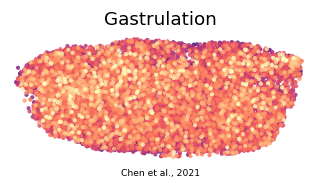

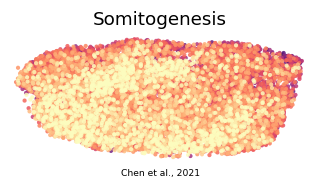

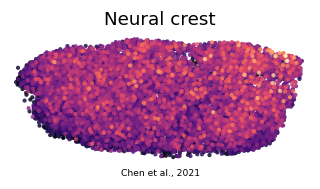

In [3]:
sig = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural crest'}
allv = np.concatenate([adata.obs[k].values for k in sig])
vmin, vmax = np.percentile(allv, [2, 98])
for key, nice in sig.items():
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=key, cmap='magma', size=30, alpha=.85, vmin=vmin, vmax=vmax,
               colorbar_loc=None, frameon=False, show=False, ax=ax, title=nice)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Chen et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{key}_signature.pdf'), bbox_inches='tight')
    print('saved', f'{key}_signature.pdf')

saved colorbars/R_colorbar.pdf | scale [-0.13, 0.10]


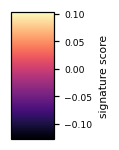

In [4]:
# shared colorbar (deliverable)
fig, ax = plt.subplots(figsize=(0.5,1.5))
cb = mpl.colorbar.ColorbarBase(ax, cmap=plt.get_cmap('magma'),
        norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
cb.set_label('signature score', size=7); cb.ax.tick_params(labelsize=6)
fig.savefig(os.path.join(pth_cb, 'R_colorbar.pdf'), bbox_inches='tight')
print('saved colorbars/R_colorbar.pdf | scale [%.2f, %.2f]' % (vmin, vmax))

### Gate 2 — module gradients along pseudotime
Quantitative readout on the **raw** scores: Somitogenesis and Gastrulation decline from the
root while Neural-crest rises to a terminal peak. Coherent, monotone, interpretable
territory → **Gate 2 GO**. No Gast/pSom co-expressing hub exists (their spatial
correlation ≈ 0), so there is no bifurcation to test → **Gate 3 NA**.

In [5]:
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
for key, nice in sig.items():
    rho,p = spearmanr(t, adata.obs[key]); print(f'{nice:14s}: rho={rho:+.3f} p={p:.1e}')
hi = adata.obs['Crest'] >= adata.obs['Crest'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print('Gate 2: pSom->Crest inverse gradient, monotone & terminal -> GO ; Gate 3: no hub -> NA')

Gastrulation  : rho=-0.029 p=4.6e-04
Somitogenesis : rho=-0.124 p=4.1e-50
Neural crest  : rho=+0.141 p=7.0e-64
Neural-crest-high decile mean pseudotime = 0.60 (terminal if ~1)
Gate 2: pSom->Crest inverse gradient, monotone & terminal -> GO ; Gate 3: no hub -> NA
